In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully!")
print("Current folder:", os.getcwd())
print("Files:", os.listdir())

All libraries imported successfully!
Current folder: /drive/notebooks
Files: ['Intro.ipynb', 'r.ipynb', 'Lorenz.ipynb', 'Mandelbrot.ipynb', 'sqlite.ipynb', 'cpp.ipynb', 'cpp-third-party-libs.ipynb', 'cpp-tiny-ray-tracer.ipynb']


In [6]:
import os

print("Current folder:", os.getcwd())
print("Files available:", os.listdir())

Current folder: /drive/notebooks
Files available: ['Intro.ipynb', 'r.ipynb', 'Lorenz.ipynb', 'Mandelbrot.ipynb', 'sqlite.ipynb', 'cpp.ipynb', 'cpp-third-party-libs.ipynb', 'cpp-tiny-ray-tracer.ipynb']


In [8]:
import os

print("Current folder:", os.getcwd())
print("\nAvailable files:")
print(os.listdir())

Current folder: /drive/notebooks

Available files:
['Intro.ipynb', 'r.ipynb', 'Lorenz.ipynb', 'Mandelbrot.ipynb', 'sqlite.ipynb', 'cpp.ipynb', 'cpp-third-party-libs.ipynb', 'cpp-tiny-ray-tracer.ipynb']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load the dataset
df = pd.read_csv("HR_Analytics.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1480, 38)


,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,RM297,18,18-25,Yes,Travel_Rarely,230,Research & Development,3,3,Life Sciences,...,3,80,0,0,2,3,0,0,0,0.0
1,RM302,18,18-25,No,Travel_Rarely,812,Sales,10,3,Medical,...,1,80,0,0,2,3,0,0,0,0.0
2,RM458,18,18-25,Yes,Travel_Frequently,1306,Sales,5,3,Marketing,...,4,80,0,0,3,3,0,0,0,0.0
3,RM728,18,18-25,No,Non-Travel,287,Research & Development,5,2,Life Sciences,...,4,80,0,0,2,3,0,0,0,0.0
4,RM829,18,18-25,Yes,Non-Travel,247,Research & Development,8,1,Medical,...,4,80,0,0,0,3,0,0,0,0.0


In [3]:
# Step 2: Data Quality Check

print("1. Dataset Information")
print("----------------------")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\n2. Missing Values")
print("----------------------")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\n3. Duplicate Records")
print("----------------------")
print("Total Duplicate Rows:", df.duplicated().sum())

print("\n4. Attrition Count")
print("----------------------")
print(df["Attrition"].value_counts(dropna=False))

print("\n5. Column Names")
print("----------------------")
print(df.columns.tolist())

1. Dataset Information
----------------------
Total Rows: 1480
Total Columns: 38

2. Missing Values
----------------------
YearsWithCurrManager        57
RelationshipSatisfaction     0
SalarySlab                   0
MonthlyRate                  0
NumCompaniesWorked           0
Over18                       0
OverTime                     0
PercentSalaryHike            0
PerformanceRating            0
StandardHours                0
Age                          0
StockOptionLevel             0
TotalWorkingYears            0
TrainingTimesLastYear        0
WorkLifeBalance              0
dtype: int64

3. Duplicate Records
----------------------
Total Duplicate Rows: 7

4. Attrition Count
----------------------
Attrition
No     1242
Yes     238
Name: count, dtype: int64

5. Column Names
----------------------
['EmpID', 'Age', 'AgeGroup', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSa

In [4]:
# STEP 3: DATA CLEANING

# Create a separate copy
df_clean = df.copy()

# Check missing values
print("Missing values before cleaning:")
print(df_clean.isnull().sum().sort_values(ascending=False).head(10))

# Fill missing manager-experience values with the median
median_value = df_clean["YearsWithCurrManager"].median()

df_clean["YearsWithCurrManager"] = (
    df_clean["YearsWithCurrManager"].fillna(median_value)
)

# Remove exact duplicate rows from the copy
df_clean = df_clean.drop_duplicates()

# Display results
print("\nData Cleaning Completed!")
print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum().sort_values(ascending=False).head(10))

print("\nCleaned dataset shape:", df_clean.shape)

Missing values before cleaning:
YearsWithCurrManager        57
RelationshipSatisfaction     0
SalarySlab                   0
MonthlyRate                  0
NumCompaniesWorked           0
Over18                       0
OverTime                     0
PercentSalaryHike            0
PerformanceRating            0
StandardHours                0
dtype: int64

Data Cleaning Completed!
Original rows: 1480
Rows after removing duplicates: 1473

Missing values after cleaning:
EmpID                       0
RelationshipSatisfaction    0
SalarySlab                  0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
StandardHours               0
dtype: int64

Cleaned dataset shape: (1473, 38)


OVERALL ATTRITION ANALYSIS
--------------------------
Total employee records: 1473
Employees who left: 237
Employees who stayed: 1236
Overall attrition rate: 16.09%


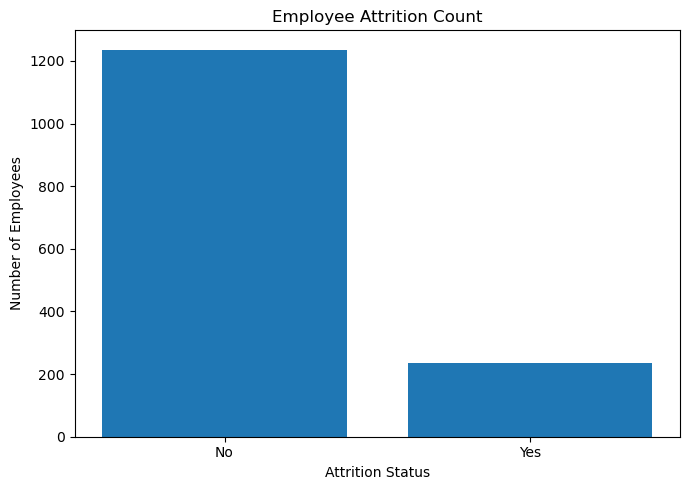

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Overall Attrition Analysis
attrition_counts = df_clean["Attrition"].value_counts()

total_employees = len(df_clean)
employees_left = (df_clean["Attrition"] == "Yes").sum()
employees_stayed = (df_clean["Attrition"] == "No").sum()

attrition_rate = (employees_left / total_employees) * 100

print("OVERALL ATTRITION ANALYSIS")
print("--------------------------")
print("Total employee records:", total_employees)
print("Employees who left:", employees_left)
print("Employees who stayed:", employees_stayed)
print(f"Overall attrition rate: {attrition_rate:.2f}%")

# Bar chart
plt.figure(figsize=(7, 5))
plt.bar(attrition_counts.index, attrition_counts.values)

plt.title("Employee Attrition Count")
plt.xlabel("Attrition Status")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

DEPARTMENT-WISE ATTRITION ANALYSIS
----------------------------------


Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,830,133
Sales,355,92



Attrition Rate by Department (%)


Department
Human Resources           19.05
Research & Development    13.81
Sales                     20.58
Name: Left, dtype: float64

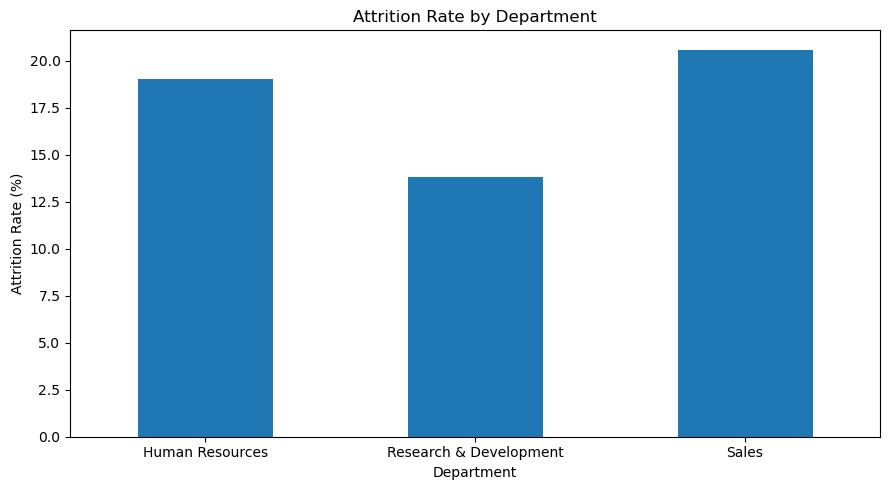

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Department-wise Attrition Analysis

department_attrition = pd.crosstab(
    df_clean["Department"],
    df_clean["Attrition"]
)

print("DEPARTMENT-WISE ATTRITION ANALYSIS")
print("----------------------------------")
display(department_attrition)

# Calculate attrition rate by department
department_rate = (
    df_clean.assign(
        Left=df_clean["Attrition"].eq("Yes")
    )
    .groupby("Department")["Left"]
    .mean() * 100
)

print("\nAttrition Rate by Department (%)")
display(department_rate.round(2))

# Create chart
plt.figure(figsize=(9, 5))

department_rate.plot(kind="bar")

plt.title("Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

OVERTIME VS ATTRITION ANALYSIS
--------------------------------


Attrition,No,Yes
OverTime,,
No,947,110
Yes,289,127



Attrition Rate by Overtime (%)


OverTime
No     10.41
Yes    30.53
Name: Left, dtype: float64

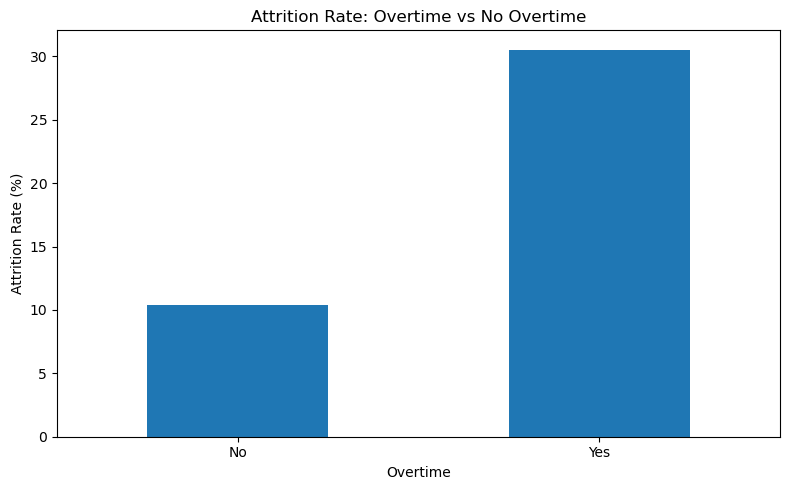

In [9]:
# STEP 6: OVERTIME VS ATTRITION ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt

# Count employees by overtime and attrition
overtime_analysis = pd.crosstab(
    df_clean["OverTime"],
    df_clean["Attrition"]
)

print("OVERTIME VS ATTRITION ANALYSIS")
print("--------------------------------")
display(overtime_analysis)

# Calculate attrition rate for each overtime group
overtime_rate = (
    df_clean.assign(
        Left=df_clean["Attrition"].eq("Yes")
    )
    .groupby("OverTime")["Left"]
    .mean() * 100
)

print("\nAttrition Rate by Overtime (%)")
display(overtime_rate.round(2))

# Create bar chart
plt.figure(figsize=(8, 5))

overtime_rate.plot(kind="bar")

plt.title("Attrition Rate: Overtime vs No Overtime")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

AGE GROUP VS ATTRITION ANALYSIS
--------------------------------


Attrition,No,Yes
AgeGroup,,
18-25,79,44
26-35,491,116
36-45,427,43
46-55,200,26
55+,39,8



Attrition Rate by Age Group (%)


AgeGroup
18-25    35.77
26-35    19.11
36-45     9.15
46-55    11.50
55+      17.02
Name: Left, dtype: float64

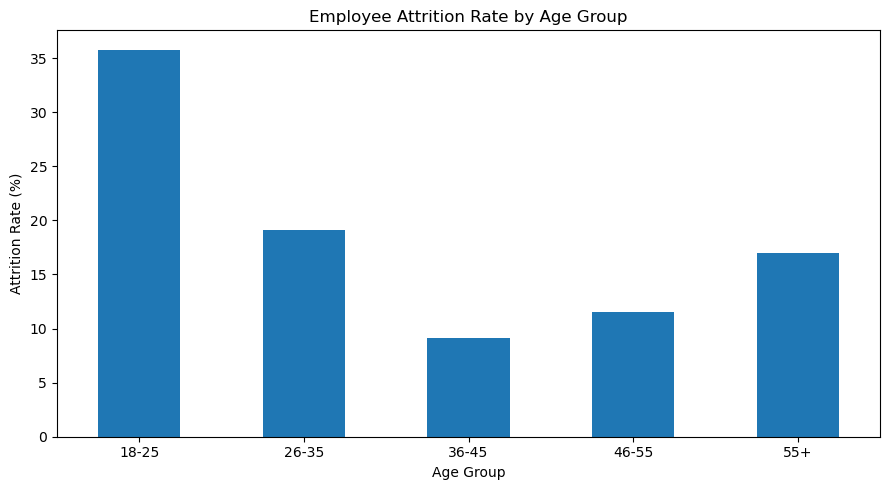

In [10]:
# STEP 7: AGE GROUP VS ATTRITION ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt

# Count employees by age group and attrition
age_analysis = pd.crosstab(
    df_clean["AgeGroup"],
    df_clean["Attrition"]
)

print("AGE GROUP VS ATTRITION ANALYSIS")
print("--------------------------------")
display(age_analysis)

# Calculate attrition rate for each age group
age_rate = (
    df_clean.assign(
        Left=df_clean["Attrition"].eq("Yes")
    )
    .groupby("AgeGroup")["Left"]
    .mean() * 100
)

print("\nAttrition Rate by Age Group (%)")
display(age_rate.round(2))

# Create bar chart
plt.figure(figsize=(9, 5))

age_rate.plot(kind="bar")

plt.title("Employee Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()



SALARY SLAB VS ATTRITION
------------------------


Attrition,No,Yes
SalarySlab,,
10k-15k,128,20
15k+,128,5
5k-10k,392,49
Upto 5k,588,163



Attrition Rate by Salary Slab (%)


SalarySlab
10k-15k    13.51
15k+        3.76
5k-10k     11.11
Upto 5k    21.70
Name: Left, dtype: float64

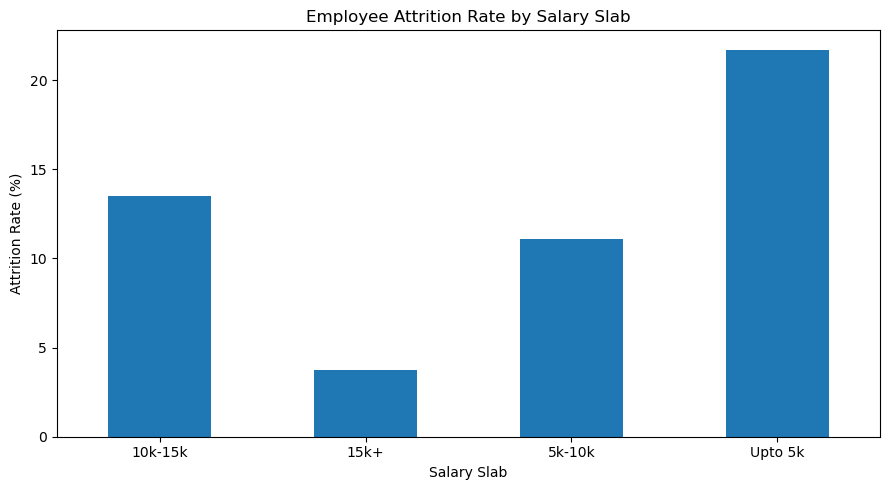

In [11]:
# STEP 8: SALARY SLAB ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt

# Count employees in each salary group
salary_analysis = pd.crosstab(
    df_clean["SalarySlab"],
    df_clean["Attrition"]
)

print("SALARY SLAB VS ATTRITION")
print("------------------------")
display(salary_analysis)

# Calculate attrition rate
salary_rate = (
    df_clean.assign(
        Left=df_clean["Attrition"].eq("Yes")
    )
    .groupby("SalarySlab")["Left"]
    .mean() * 100
)

print("\nAttrition Rate by Salary Slab (%)")
display(salary_rate.round(2))

# Create chart
plt.figure(figsize=(9, 5))

salary_rate.plot(kind="bar")

plt.title("Employee Attrition Rate by Salary Slab")
plt.xlabel("Salary Slab")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Marital Status vs Attrition:


Attrition,No,Yes
MaritalStatus,,
Divorced,294,33
Married,591,84
Single,351,120



Attrition Rate by Marital Status (%):


MaritalStatus
Divorced    10.09
Married     12.44
Single      25.48
Name: Left, dtype: float64

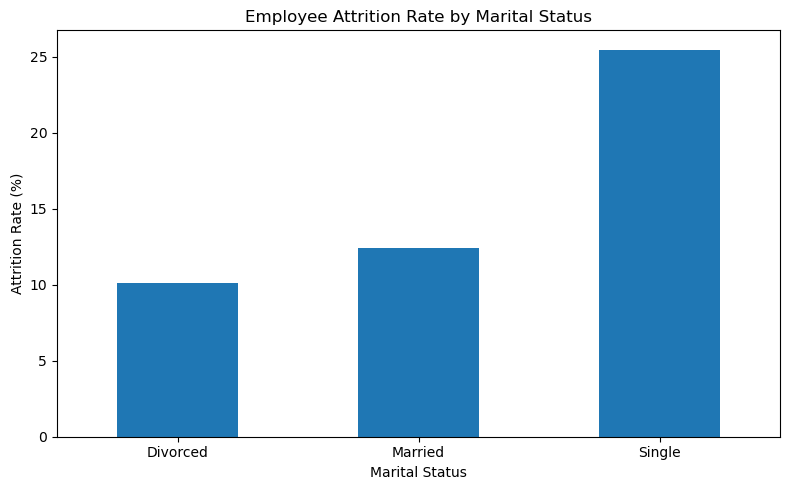

In [12]:
# Step 9: Marital Status Analysis

marital_analysis = pd.crosstab(
    df_clean["MaritalStatus"],
    df_clean["Attrition"]
)

print("Marital Status vs Attrition:")
display(marital_analysis)

# Calculate attrition rate
marital_rate = (
    df_clean.assign(Left=df_clean["Attrition"].eq("Yes"))
    .groupby("MaritalStatus")["Left"]
    .mean() * 100
)

print("\nAttrition Rate by Marital Status (%):")
display(marital_rate.round(2))

# Create chart
plt.figure(figsize=(8, 5))
marital_rate.plot(kind="bar")
plt.title("Employee Attrition Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Job Role vs Attrition:


Attrition,No,Yes
JobRole,,
Healthcare Representative,123,9
Human Resources,40,12
Laboratory Technician,198,62
Manager,97,5
Manufacturing Director,135,10
Research Director,78,2
Research Scientist,245,47
Sales Executive,269,57
Sales Representative,51,33



Attrition Rate by Job Role (%):


JobRole
Healthcare Representative     6.82
Human Resources              23.08
Laboratory Technician        23.85
Manager                       4.90
Manufacturing Director        6.90
Research Director             2.50
Research Scientist           16.10
Sales Executive              17.48
Sales Representative         39.29
Name: Left, dtype: float64

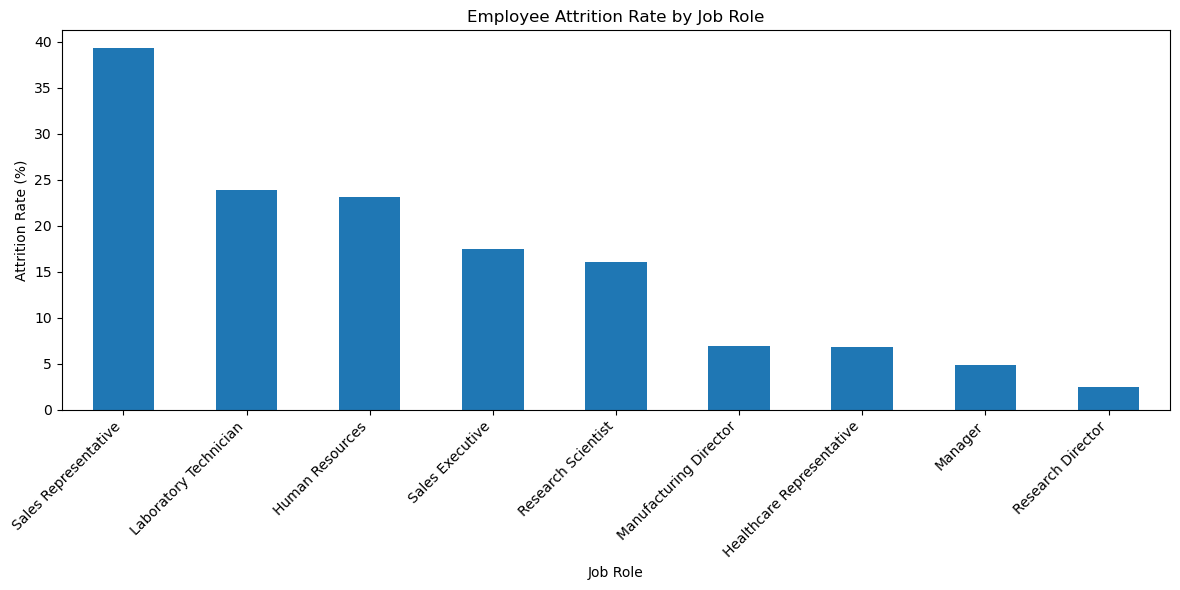

In [13]:
# Step 10: Job Role Analysis

job_role_analysis = pd.crosstab(
    df_clean["JobRole"],
    df_clean["Attrition"]
)

print("Job Role vs Attrition:")
display(job_role_analysis)

# Calculate attrition rate by job role
job_role_rate = (
    df_clean.assign(Left=df_clean["Attrition"].eq("Yes"))
    .groupby("JobRole")["Left"]
    .mean() * 100
)

print("\nAttrition Rate by Job Role (%):")
display(job_role_rate.round(2))

# Create bar chart
plt.figure(figsize=(12, 6))
job_role_rate.sort_values(ascending=False).plot(kind="bar")

plt.title("Employee Attrition Rate by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Business Travel vs Attrition:


Attrition,No,Yes
BusinessTravel,,
Non-Travel,138,12
TravelRarely,7,0
Travel_Frequently,209,69
Travel_Rarely,882,156



Attrition Rate by Business Travel (%):


BusinessTravel
Non-Travel            8.00
TravelRarely          0.00
Travel_Frequently    24.82
Travel_Rarely        15.03
Name: Left, dtype: float64

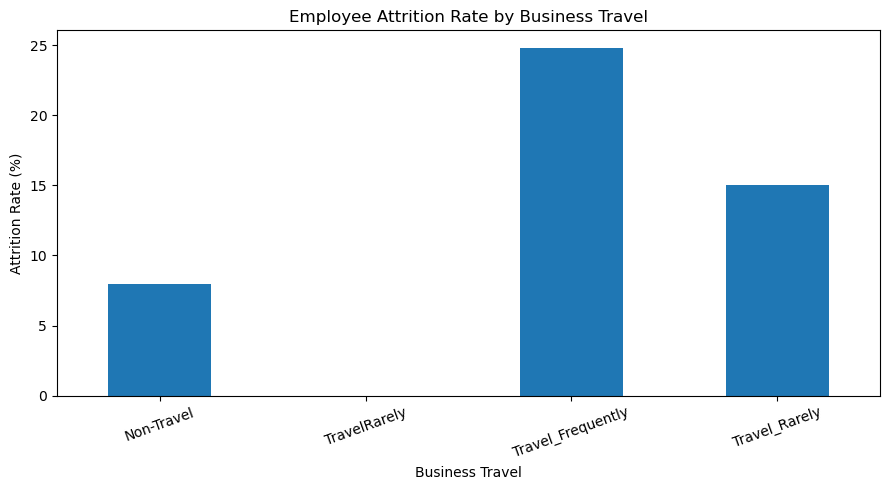

In [14]:
# Step 11: Business Travel Analysis

travel_analysis = pd.crosstab(
df_clean["BusinessTravel"],
df_clean["Attrition"]
)

print("Business Travel vs Attrition:")
display(travel_analysis)

# Calculate attrition rate

travel_rate = (
df_clean.assign(Left=df_clean["Attrition"].eq("Yes"))
.groupby("BusinessTravel")["Left"]
.mean() * 100
)

print("\nAttrition Rate by Business Travel (%):")
display(travel_rate.round(2))

# Create chart

plt.figure(figsize=(9, 5))
travel_rate.plot(kind="bar")
plt.title("Employee Attrition Rate by Business Travel")
plt.xlabel("Business Travel")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


Education Field vs Attrition:


Attrition,No,Yes
EducationField,,
Human Resources,20,7
Life Sciences,517,89
Marketing,124,35
Medical,403,63
Other,72,11
Technical Degree,100,32



Attrition Rate by Education Field (%):


EducationField
Human Resources     25.93
Life Sciences       14.69
Marketing           22.01
Medical             13.52
Other               13.25
Technical Degree    24.24
Name: Left, dtype: float64

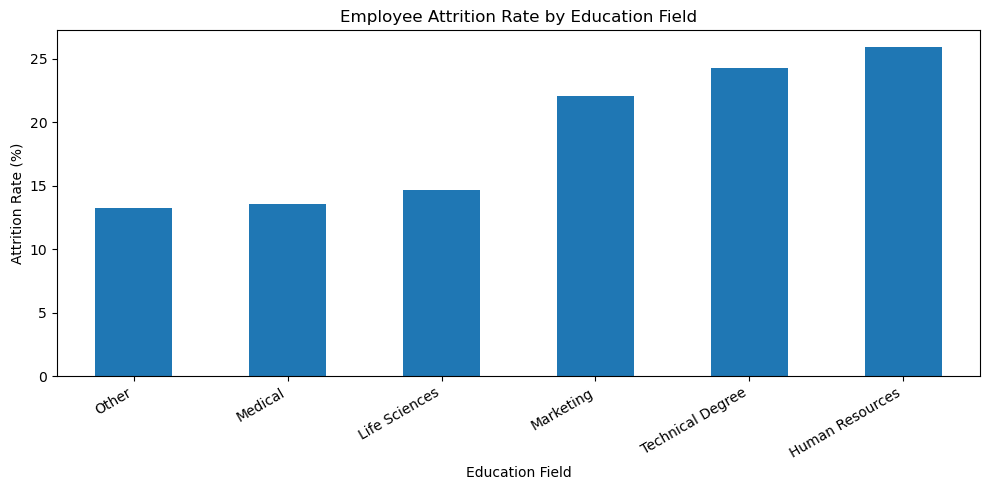

In [15]:
# Step 12: Education Field Analysis

education_analysis = pd.crosstab(
df_clean["EducationField"],
df_clean["Attrition"]
)

print("Education Field vs Attrition:")
display(education_analysis)

# Calculate attrition rate

education_rate = (
df_clean.assign(Left=df_clean["Attrition"].eq("Yes"))
.groupby("EducationField")["Left"]
.mean() * 100
)

print("\nAttrition Rate by Education Field (%):")
display(education_rate.round(2))

# Create chart

plt.figure(figsize=(10, 5))
education_rate.sort_values().plot(kind="bar")
plt.title("Employee Attrition Rate by Education Field")
plt.xlabel("Education Field")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [16]:
# Step 13: Final Summary and Key Findings

total_employees = len(df_clean)
employees_left = (df_clean["Attrition"] == "Yes").sum()
employees_stayed = (df_clean["Attrition"] == "No").sum()
overall_attrition_rate = employees_left / total_employees * 100

print("========== HR ANALYTICS PROJECT SUMMARY ==========")
print("Total Employees:", total_employees)
print("Employees Who Left:", employees_left)
print("Employees Who Stayed:", employees_stayed)
print("Overall Attrition Rate:", round(overall_attrition_rate, 2), "%")

# Highest attrition by marital status

marital_rate = (
df_clean.assign(Left=df_clean["Attrition"].eq("Yes"))
.groupby("MaritalStatus")["Left"]
.mean() * 100
)

print("\nHighest Attrition by Marital Status:")
print(marital_rate.idxmax(), "-", round(marital_rate.max(), 2), "%")

# Highest attrition by business travel

travel_rate = (
df_clean.assign(Left=df_clean["Attrition"].eq("Yes"))
.groupby("BusinessTravel")["Left"]
.mean() * 100
)

print("\nHighest Attrition by Business Travel:")
print(travel_rate.idxmax(), "-", round(travel_rate.max(), 2), "%")

# Highest attrition by education field

education_rate = (
df_clean.assign(Left=df_clean["Attrition"].eq("Yes"))
.groupby("EducationField")["Left"]
.mean() * 100
)

print("\nHighest Attrition by Education Field:")
print(education_rate.idxmax(), "-", round(education_rate.max(), 2), "%")

print("\nRecommendation: Investigate employee satisfaction, workload,")
print("career growth, compensation, and overtime patterns.")
print("Use these findings as patterns, not proof of causation.")


========== HR ANALYTICS PROJECT SUMMARY ==========
Total Employees: 1473
Employees Who Left: 237
Employees Who Stayed: 1236
Overall Attrition Rate: 16.09 %

Highest Attrition by Marital Status:
Single - 25.48 %

Highest Attrition by Business Travel:
Travel_Frequently - 24.82 %

Highest Attrition by Education Field:
Human Resources - 25.93 %

Recommendation: Investigate employee satisfaction, workload,
career growth, compensation, and overtime patterns.
Use these findings as patterns, not proof of causation.


<ipython-input-17-26a99be032c7>:16: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("HR_Analytics_Graphs/01_Overall_Attrition.png", dpi=300)
<ipython-input-17-26a99be032c7>:16: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("HR_Analytics_Graphs/01_Overall_Attrition.png", dpi=300)


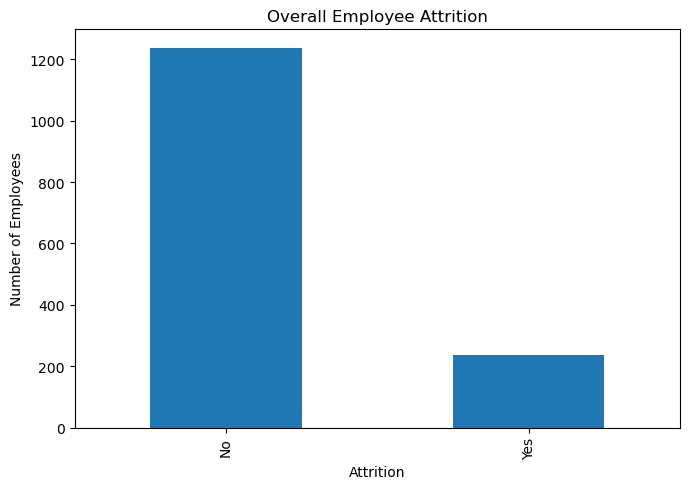

<ipython-input-17-26a99be032c7>:32: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("HR_Analytics_Graphs/02_Department_Attrition.png", dpi=300)
<ipython-input-17-26a99be032c7>:32: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("HR_Analytics_Graphs/02_Department_Attrition.png", dpi=300)


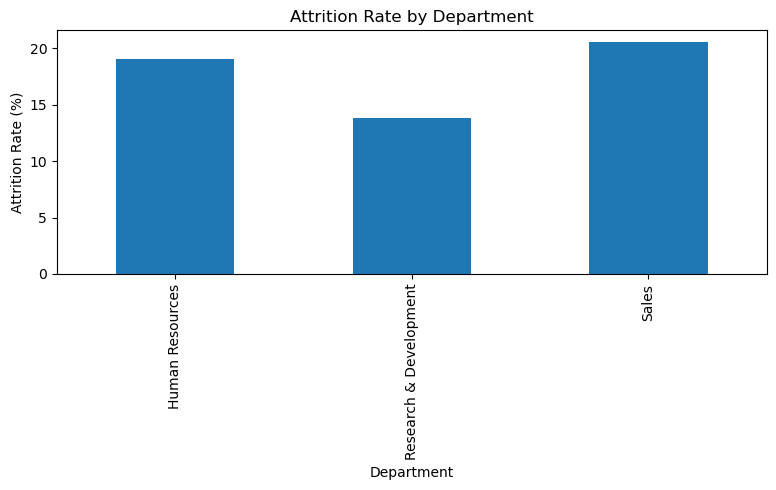

<ipython-input-17-26a99be032c7>:48: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("HR_Analytics_Graphs/03_Overtime_Attrition.png", dpi=300)
<ipython-input-17-26a99be032c7>:48: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("HR_Analytics_Graphs/03_Overtime_Attrition.png", dpi=300)


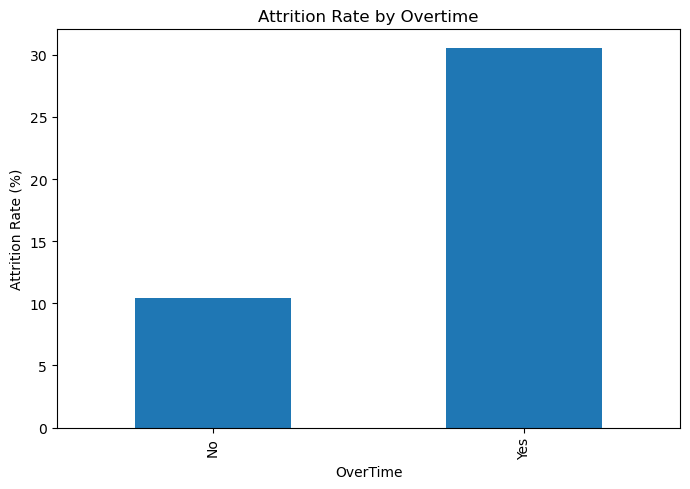

Graphs saved successfully!
Folder: HR_Analytics_Graphs


In [17]:
import os
import matplotlib.pyplot as plt

# Create a folder for project graphs

os.makedirs("HR_Analytics_Graphs", exist_ok=True)

# 1. Overall Attrition

plt.figure(figsize=(7, 5))
df_clean["Attrition"].value_counts().plot(kind="bar")
plt.title("Overall Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.savefig("HR_Analytics_Graphs/01_Overall_Attrition.png", dpi=300)
plt.show()

# 2. Department-wise Attrition Rate

department_rate = (
df_clean.assign(Left=df_clean["Attrition"].eq("Yes"))
.groupby("Department")["Left"].mean() * 100
)

plt.figure(figsize=(8, 5))
department_rate.plot(kind="bar")
plt.title("Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.savefig("HR_Analytics_Graphs/02_Department_Attrition.png", dpi=300)
plt.show()

# 3. Overtime-wise Attrition Rate

overtime_rate = (
df_clean.assign(Left=df_clean["Attrition"].eq("Yes"))
.groupby("OverTime")["Left"].mean() * 100
)

plt.figure(figsize=(7, 5))
overtime_rate.plot(kind="bar")
plt.title("Attrition Rate by Overtime")
plt.xlabel("OverTime")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.savefig("HR_Analytics_Graphs/03_Overtime_Attrition.png", dpi=300)
plt.show()

print("Graphs saved successfully!")
print("Folder: HR_Analytics_Graphs")
